In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("data loaded successfully!")


data loaded successfully!


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

#rows and columns
print(df.shape)
#Display column names
print(df.columns)
#Check data types
df.info()
#missing values
print(df.isnull().sum())


(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non

In [ ]:
#DATA CLEANING WITH EDA(EXPLORATORY DATA ANALYSIS)

print("Number of rows and columns:")
print(df.shape)
print("Total customers:")
print(len(df))

Number of rows and columns:
(7043, 21)
Total customers:
7043


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
#check missing values
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
#check dupicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
#clean the datsset
df_clean = df.copy()
print("Original dataset preserved!")
print("Working with cleaned dataset.")

Original dataset preserved!
Working with cleaned dataset.


In [ ]:
#remove extra spaces
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()
print("Extra spaces removed!")

Extra spaces removed!


In [ ]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print(df_clean["TotalCharges"].dtype)


float64


In [ ]:
#handle missing ValuesView

print("Missing values before cleaning:")
print(df_clean.isnull().sum())

df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values before cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
C

In [ ]:
#remove dupicate records
df_clean = df_clean.drop_duplicates()

print("Remaining duplicate rows:")
print(df_clean.duplicated().sum())

Remaining duplicate rows:
0


In [ ]:

total_customers = len(df_clean)

print("Total Customers:", total_customers)


Total Customers: 7043


In [ ]:

print(df_clean["Churn"].value_counts())


Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:

churn_count = (df_clean["Churn"] == "Yes").sum()

churn_rate = (churn_count / len(df_clean)) * 100

print("Churn Rate:", round(churn_rate, 2), "%")


Churn Rate: 26.54 %


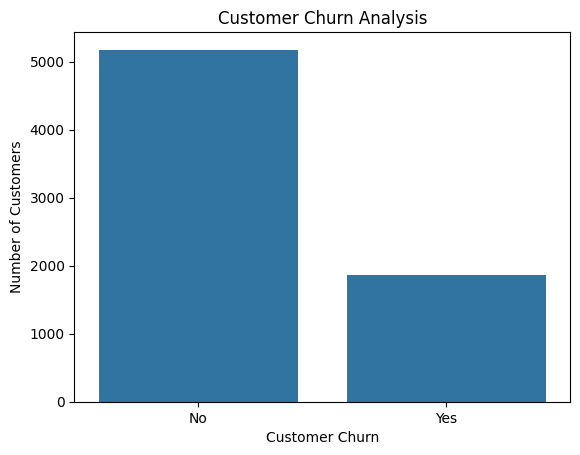

In [ ]:
#churn graph
sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Analysis")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()


Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


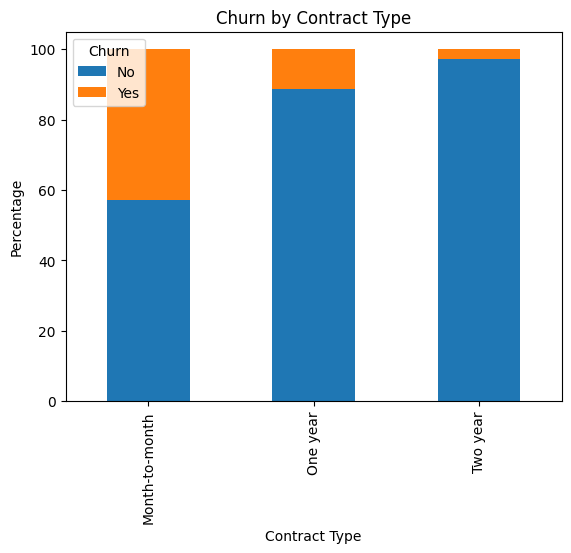

In [ ]:

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print(contract_churn)

contract_churn.plot(
    kind="bar",
    stacked=True
)

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")

plt.show()


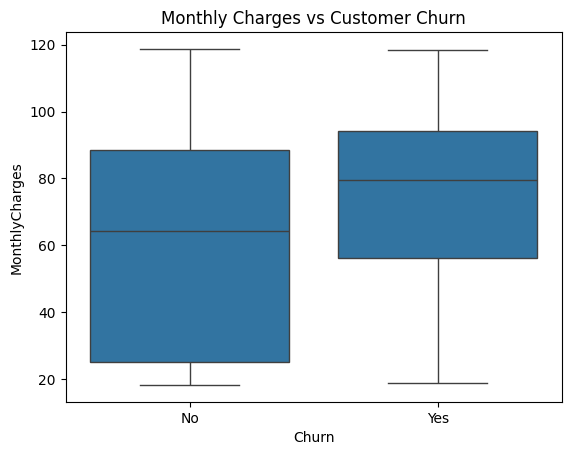

In [ ]:

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.show()


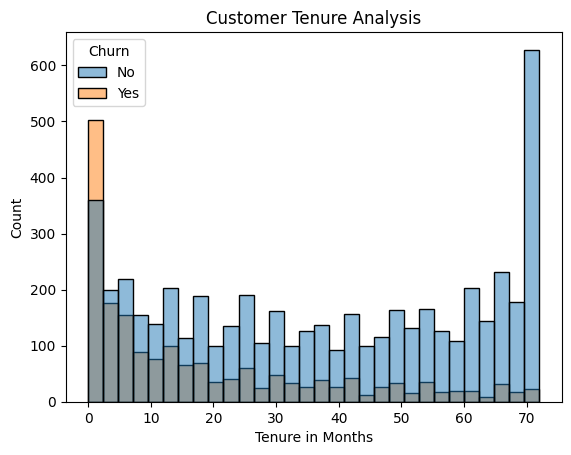

In [ ]:

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30
)

plt.title("Customer Tenure Analysis")
plt.xlabel("Tenure in Months")

plt.show()


In [ ]:

df_clean.to_csv("telco_churn_clean.csv", index=False)

print("CSV file exported successfully!")


CSV file exported successfully!


In [ ]:
df_clean.to_csv("telco_churn_clean.csv", index=False)

In [ ]:
print(df_clean.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [ ]:
print(df_clean.shape)

(7043, 21)


In [ ]:
print(df_clean.shape)

(7043, 21)


In [ ]:
# Remove customer ID
df_ml = df_clean.drop("customerID", axis=1)

# Separate input and output
X = df_ml.drop("Churn", axis=1)
y = df_ml["Churn"].map({"Yes": 1, "No": 0})

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (7043, 19)
Output shape: (7043,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [ ]:
# Convert categorical columns into numerical columns
X_train_encoded = pd.get_dummies(X_train, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

# Make sure both datasets have the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (5634, 30)
Testing data shape: (1409, 30)


In [ ]:
print(X_train_encoded.head())

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
3738              0      35           49.20       1701.65         True   
3151              0      15           75.10       1151.55         True   
4860              0      13           40.55        590.35         True   
3867              0      26           73.50       1905.70        False   
3810              0       1           44.55         44.55         True   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
3738        False           False             False   
3151         True            True              True   
4860         True            True             False   
3867         True           False              True   
3810         True            True              True   

      MultipleLines_No phone service  MultipleLines_Yes  ...  \
3738                            True              False  ...   
3151                           False              False  ...   
4860                            

In [ ]:
print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (5634, 30)
Testing data shape: (1409, 30)


In [ ]:
#logestic regression
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_encoded, y_train)

print("Model training completed!")

Model training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_pred = model.predict(X_test_encoded)

print("First 10 predictions:", y_pred[:10])

First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 80.48 %


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[926 109]
 [166 208]]


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [ ]:
y_probability = model.predict_proba(X_test_encoded)[:, 1]

roc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", round(roc, 3))

ROC-AUC Score: 0.843


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
rf_pred = rf_model.predict(X_test_encoded)

print("First 10 predictions:", rf_pred[:10])

First 10 predictions: [0 1 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 79.13 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

rf_probability = rf_model.predict_proba(X_test_encoded)[:, 1]

print("ROC-AUC Score:", round(
    roc_auc_score(y_test, rf_probability), 3
))

Confusion Matrix:
[[931 104]
 [190 184]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

ROC-AUC Score: 0.822


In [ ]:
print("MODEL COMPARISON")

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

MODEL COMPARISON
Logistic Regression Accuracy: 80.48 %
Random Forest Accuracy: 79.13 %


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Display top 10 features
print(feature_importance.head(10))

                           Feature  Importance
3                     TotalCharges    0.176560
1                           tenure    0.165450
2                   MonthlyCharges    0.153867
25               Contract_Two year    0.059710
10     InternetService_Fiber optic    0.040670
28  PaymentMethod_Electronic check    0.036171
13              OnlineSecurity_Yes    0.031538
24               Contract_One year    0.029769
4                      gender_Male    0.025485
26            PaperlessBilling_Yes    0.023924


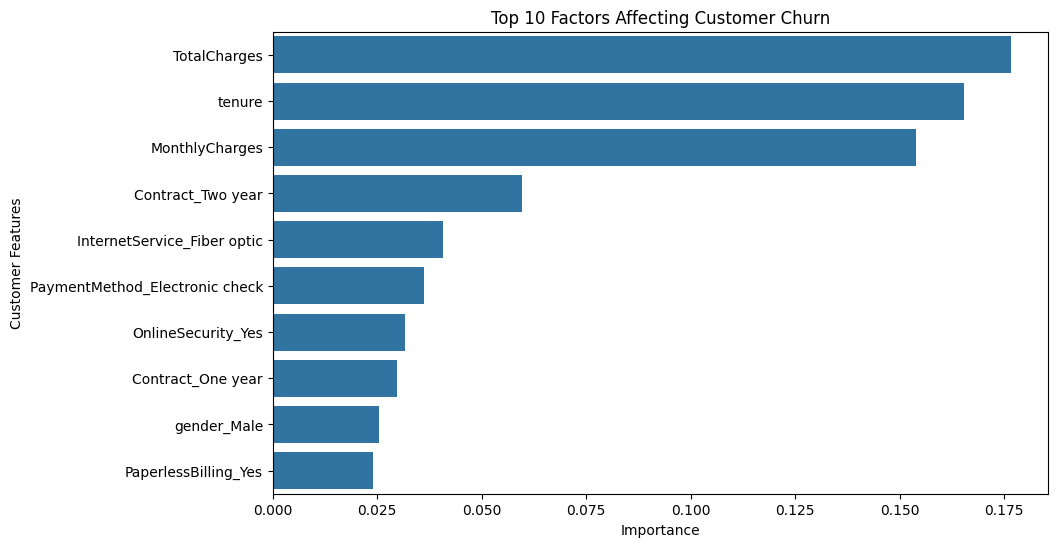

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Factors Affecting Customer Churn")
plt.xlabel("Importance")
plt.ylabel("Customer Features")

plt.show()

In [ ]:
import joblib

joblib.dump(rf_model, "customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
feature_importance.to_csv(
    "churn_feature_importance.csv",
    index=False
)

files.download("churn_feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>